# 02 - Transform macro data

Build the monthly model table for the CPI nowcast from `data/raw/macro_monthly_raw.csv` (notebook 01).


## 0. Imports and CONFIG

All team decisions live in this cell.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# ---------------- CONFIG ----------------
# Target: y = 100 * diff(log(cpi)), monthly CPI change in percent.
# y_annualized = 100 * ((1 + y/100)**12 - 1) is for reporting only, never a feature.
N_CPI_LAGS = 3
MA_WINDOW = 12

TRAIN_START, TRAIN_END = "1999-01-01", "2019-12-31"
TEST_START, TEST_END = "2020-01-01", "2023-12-31"

# Months of delay before a series can be used to nowcast month t at the END of month t.
# These are DEFAULTS and still need to be confirmed against the FRED release calendars.
AVAILABILITY_LAG = {
    "cpi_core": 1,
    "ppi": 1,
    "housing": 1,
    "payems": 1,
    "exp": 1,
    "oil": 0,
    "gas": 0,
}

# Raw columns turned into 100 * diff(log(x)); exp (MICH) stays in levels.
LOG_DIFF_COLS = ["cpi_core", "ppi", "housing", "payems",
                 "oil_mean", "oil_last", "gas_mean", "gas_last"]
LEVEL_COLS = ["exp"]

FRED_IDS = {
    "cpi": "CPIAUCSL", "cpi_core": "CPILFESL", "oil": "DCOILWTICO",
    "gas": "GASREGW", "exp": "MICH", "ppi": "PPIACO",
    "housing": "HOUST", "payems": "PAYEMS",
}
OUTLIER_SD = 4
LEAKAGE_TEST_DATES = ["2005-06-01", "2008-10-01", "2015-01-01",
                      "2020-04-01", "2023-12-01"]
# ----------------------------------------

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW_PATH = ROOT / "data" / "raw" / "macro_monthly_raw.csv"
OUT_DIR = ROOT / "data" / "processed"

## 1. Load and inspect

In [2]:
raw = pd.read_csv(RAW_PATH, index_col="date", parse_dates=True)
raw.index.freq = "MS"

expected_cols = {"cpi"} | set(LOG_DIFF_COLS) | set(LEVEL_COLS)
missing_cols = expected_cols - set(raw.columns)
assert not missing_cols, f"columns missing from raw data: {missing_cols}"

raw.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 312 entries, 1998-01-01 to 2023-12-01
Freq: MS
Data columns (total 10 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   cpi       312 non-null    float64
 1   cpi_core  312 non-null    float64
 2   oil_mean  312 non-null    float64
 3   oil_last  312 non-null    float64
 4   gas_mean  312 non-null    float64
 5   gas_last  312 non-null    float64
 6   exp       312 non-null    float64
 7   ppi       312 non-null    float64
 8   housing   312 non-null    float64
 9   payems    312 non-null    float64
dtypes: float64(10)
memory usage: 26.8 KB


In [3]:
display(raw.head())
display(raw.tail())
raw.isna().sum().rename("missing")

,cpi,cpi_core,oil_mean,oil_last,gas_mean,gas_last,exp,ppi,housing,payems
date,,,,,,,,,,
1998-01-01,162.0,171.6,16.696250,17.21,1.08625,1.066,2.3,125.4,1525.0,124806.0
1998-02-01,162.0,171.9,16.061176,15.44,1.04900,1.044,2.4,125.0,1584.0,125017.0
1998-03-01,162.0,172.2,15.125714,15.75,1.01680,1.030,2.5,124.7,1567.0,125165.0
1998-04-01,162.2,172.5,15.353810,15.56,1.03025,1.040,2.4,124.9,1540.0,125445.0
1998-05-01,162.6,172.9,14.923529,15.21,1.06350,1.070,2.6,125.1,1536.0,125845.0


,cpi,cpi_core,oil_mean,oil_last,gas_mean,gas_last,exp,ppi,housing,payems
date,,,,,,,,,,
2023-08-01,306.082,309.580,81.386087,83.55,3.83975,3.813,3.5,257.680,1321.0,156261.0
2023-09-01,307.276,310.539,89.425000,90.77,3.83600,3.837,3.2,258.934,1369.0,156417.0
2023-10-01,307.696,311.457,85.639524,81.64,3.61280,3.473,4.2,255.192,1380.0,156576.0
2023-11-01,308.148,312.392,77.685000,75.66,3.31800,3.238,4.5,252.856,1522.0,156703.0
2023-12-01,308.741,313.195,71.900000,71.89,3.13400,3.116,3.1,249.866,1504.0,156857.0


cpi         0
cpi_core    0
oil_mean    0
oil_last    0
gas_mean    0
gas_last    0
exp         0
ppi         0
housing     0
payems      0
Name: missing, dtype: int64

## Feature construction: `build_features(raw)`

Steps 2 to 5 all happen inside this one function, so it can be tested (see step 8). The sections below just show its output step by step.

In [4]:
def source_of(col):
    """Map a column (e.g. 'oil_mean_chg') to its source series key (e.g. 'oil')."""
    col = col.removesuffix("_chg")
    return col.split("_")[0] if col.startswith(("oil", "gas")) else col


def build_features(raw):
    """Build target and features from the raw monthly table. No row is dropped here."""
    out = pd.DataFrame(index=raw.index)

    # Target
    out["y"] = 100 * np.log(raw["cpi"]).diff()
    out["y_annualized"] = 100 * ((1 + out["y"] / 100) ** 12 - 1)

    # Step 2: monthly changes (exp stays in levels)
    changes = pd.DataFrame(index=raw.index)
    for col in LOG_DIFF_COLS:
        changes[f"{col}_chg"] = 100 * np.log(raw[col]).diff()
    for col in LEVEL_COLS:
        changes[col] = raw[col]

    # Step 3: CPI lags
    for k in range(1, N_CPI_LAGS + 1):
        out[f"y_lag{k}"] = out["y"].shift(k)

    # Step 4: rolling means of PAST values only (shift(1) keeps month t out)
    out[f"y_ma{MA_WINDOW}"] = out["y"].shift(1).rolling(MA_WINDOW).mean()
    out[f"cpi_core_chg_ma{MA_WINDOW}"] = (
        changes["cpi_core_chg"].shift(1).rolling(MA_WINDOW).mean()
    )

    # Step 5: availability lag, value at row t = value at t - lag
    for col in changes.columns:
        out[col] = changes[col].shift(AVAILABILITY_LAG[source_of(col)])

    return out


features_all = build_features(raw)
TARGET_COLS = ["y", "y_annualized"]
FEATURE_COLS = [c for c in features_all.columns if c not in TARGET_COLS]
FEATURE_COLS

['y_lag1',
 'y_lag2',
 'y_lag3',
 'y_ma12',
 'cpi_core_chg_ma12',
 'cpi_core_chg',
 'ppi_chg',
 'housing_chg',
 'payems_chg',
 'oil_mean_chg',
 'oil_last_chg',
 'gas_mean_chg',
 'gas_last_chg',
 'exp']

## 2. Monthly changes

`100 * diff(log(x))` for the level series; `exp` (MICH) kept in levels. Shown here after the availability lag of step 5.

In [5]:
change_cols = [f"{c}_chg" for c in LOG_DIFF_COLS] + LEVEL_COLS
features_all[["y"] + change_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
y,311.0,0.207365,0.302400,-1.786409,0.056248,0.210467,0.343222,1.367456
cpi_core_chg,310.0,0.193256,0.134967,-0.490992,0.114303,0.176699,0.231612,0.807534
ppi_chg,310.0,0.226230,1.206502,-5.480108,-0.388972,0.245379,0.896339,3.161962
housing_chg,310.0,-0.000635,8.123714,-30.200213,-4.997215,0.181544,5.485566,21.477530
payems_chg,310.0,0.073417,0.885310,-14.577821,0.044261,0.124071,0.189002,3.421695
oil_mean_chg,311.0,0.469483,10.303313,-56.819108,-4.721638,1.539068,6.165853,54.585244
oil_last_chg,311.0,0.459693,11.139208,-78.196499,-6.070677,1.443026,6.978076,61.503103
gas_mean_chg,311.0,0.340701,6.456143,-35.147982,-2.822172,0.218952,4.083415,18.257030
gas_last_chg,311.0,0.344899,6.966629,-33.918676,-3.151543,0.098668,4.503238,18.441017
exp,311.0,3.067846,0.741051,0.400000,2.700000,2.900000,3.200000,5.400000


## 3. CPI lags

In [6]:
lag_cols = [f"y_lag{k}" for k in range(1, N_CPI_LAGS + 1)]
features_all[["y"] + lag_cols].head(6)

,y,y_lag1,y_lag2,y_lag3
date,,,,
1998-01-01,NaN,NaN,NaN,NaN
1998-02-01,0.000000,NaN,NaN,NaN
1998-03-01,0.000000,0.000000,NaN,NaN
1998-04-01,0.123381,0.000000,0.000000,NaN
1998-05-01,0.246306,0.123381,0.000000,0.0
1998-06-01,0.122926,0.246306,0.123381,0.0


## 4. Rolling means of past values

`y.shift(1).rolling(MA_WINDOW).mean()`: the `shift(1)` makes sure month t never enters its own average.

In [7]:
ma_cols = [f"y_ma{MA_WINDOW}", f"cpi_core_chg_ma{MA_WINDOW}"]

# Sanity check: the MA at t equals the plain mean of y over t-MA_WINDOW .. t-1
t = features_all.index[30]
window = features_all["y"].loc[:t].iloc[-MA_WINDOW - 1:-1]
assert np.isclose(features_all.loc[t, f"y_ma{MA_WINDOW}"], window.mean())

features_all[["y"] + ma_cols].iloc[10:16]

,y,y_ma12,cpi_core_chg_ma12
date,,,
1998-11-01,0.121951,NaN,NaN
1998-12-01,0.182648,NaN,NaN
1999-01-01,0.182315,NaN,NaN
1999-02-01,0.000000,0.137744,0.192021
1999-03-01,0.060698,0.137744,0.177465
1999-04-01,0.665258,0.142802,0.167678


## 5. Availability lag

Each predictor at row t equals its value at t - lag (lags from CONFIG).

In [8]:
pd.Series({col: AVAILABILITY_LAG[source_of(col)] for col in change_cols},
          name="lag_months")

cpi_core_chg    1
ppi_chg         1
housing_chg     1
payems_chg      1
oil_mean_chg    0
oil_last_chg    0
gas_mean_chg    0
gas_last_chg    0
exp             1
Name: lag_months, dtype: int64

## 6. Missing data

No imputation: rows with NaN in any feature or in y are dropped.

In [9]:
n_before = len(features_all)
model_table = features_all.dropna(subset=FEATURE_COLS + ["y"])
print(f"Rows before: {n_before}, after: {len(model_table)}, "
      f"lost: {n_before - len(model_table)}")
print(f"First usable month: {model_table.index[0]:%Y-%m}")
print(f"Last usable month:  {model_table.index[-1]:%Y-%m}")
features_all.isna().sum().loc[lambda s: s > 0].rename("NaN before drop")

Rows before: 312, after: 299, lost: 13
First usable month: 1999-02
Last usable month:  2023-12


y                     1
y_annualized          1
y_lag1                2
y_lag2                3
y_lag3                4
y_ma12               13
cpi_core_chg_ma12    13
cpi_core_chg          2
ppi_chg               2
housing_chg           2
payems_chg            2
oil_mean_chg          1
oil_last_chg          1
gas_mean_chg          1
gas_last_chg          1
exp                   1
Name: NaN before drop, dtype: int64

## 7. Outliers (report only)

Flag values more than `OUTLIER_SD` standard deviations from the **training-period** mean. Nothing is removed.

In [10]:
train_mask = (model_table.index >= TRAIN_START) & (model_table.index <= TRAIN_END)
train_stats = model_table.loc[train_mask, FEATURE_COLS + ["y"]].agg(["mean", "std"])
z = (model_table[FEATURE_COLS + ["y"]] - train_stats.loc["mean"]) / train_stats.loc["std"]
flags = z.abs() > OUTLIER_SD

outlier_report = pd.DataFrame({
    "n_flagged": flags.sum(),
    "months": [", ".join(f"{d:%Y-%m}" for d in model_table.index[flags[c]])
               for c in flags.columns],
})
outlier_report[outlier_report["n_flagged"] > 0]

,n_flagged,months
y_lag1,2,"2005-10, 2008-12"
y_lag2,2,"2005-11, 2009-01"
y_lag3,2,"2005-12, 2009-02"
y_ma12,11,"2022-01, 2022-02, 2022-03, 2022-04, 2022-05, 2..."
cpi_core_chg_ma12,31,"2021-06, 2021-07, 2021-08, 2021-09, 2021-10, 2..."
cpi_core_chg,16,"2020-05, 2020-08, 2021-05, 2021-06, 2021-07, 2..."
ppi_chg,2,"2008-11, 2008-12"
payems_chg,9,"2009-02, 2009-03, 2009-04, 2020-04, 2020-05, 2..."
oil_mean_chg,3,"2020-03, 2020-04, 2020-05"
oil_last_chg,3,"2008-10, 2020-03, 2020-05"


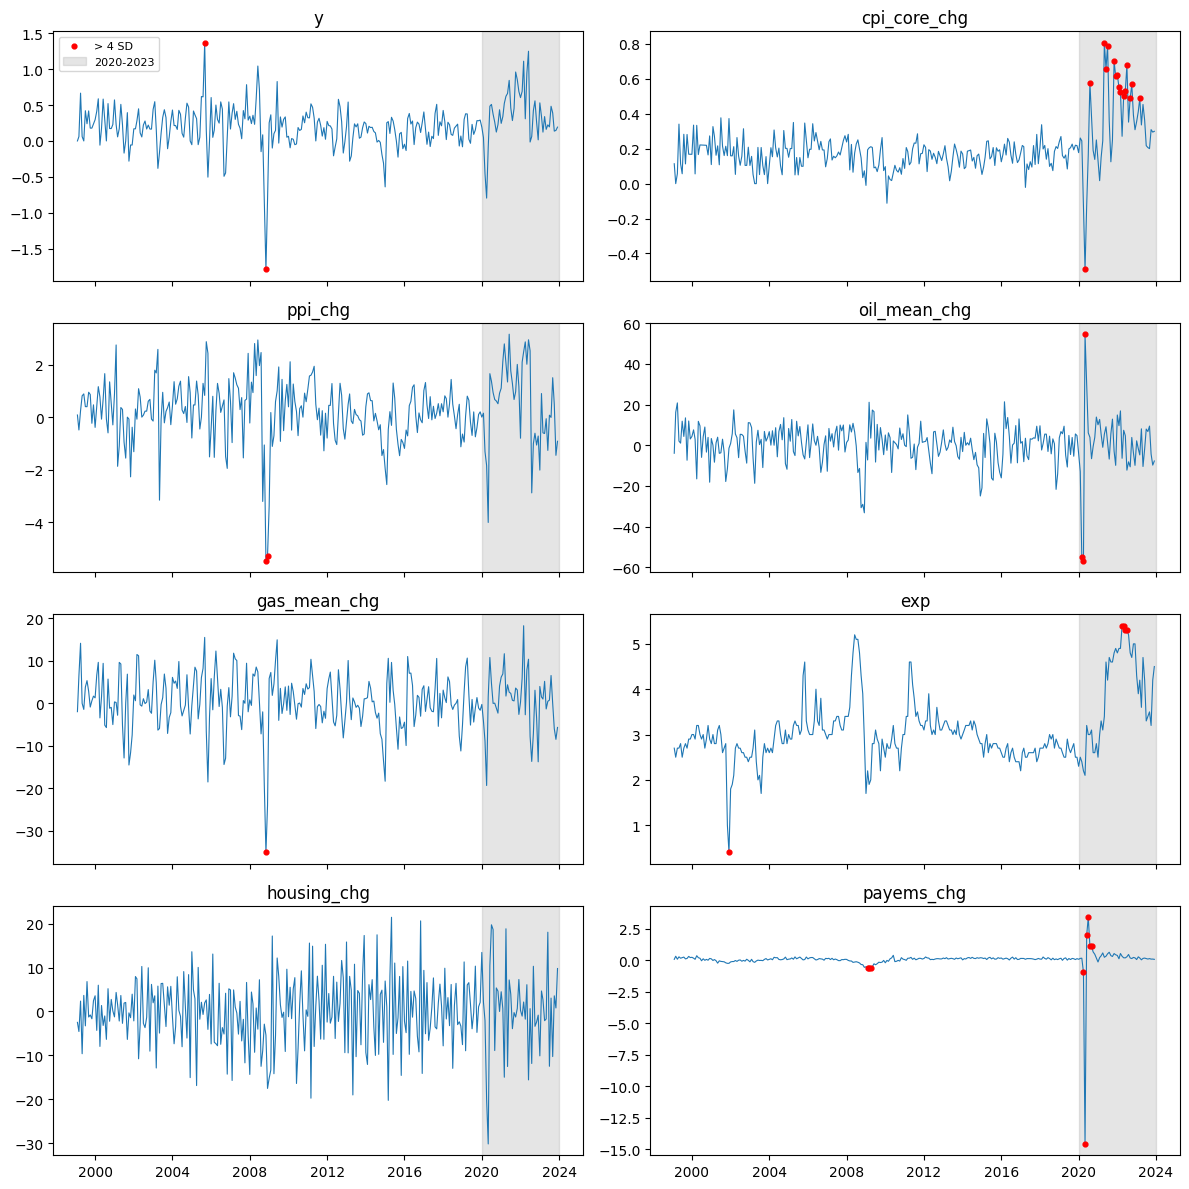

In [11]:
main_cols = ["y", "cpi_core_chg", "ppi_chg", "oil_mean_chg",
             "gas_mean_chg", "exp", "housing_chg", "payems_chg"]
fig, axes = plt.subplots(4, 2, figsize=(12, 12), sharex=True)
for ax, col in zip(axes.flat, main_cols):
    ax.plot(model_table.index, model_table[col], lw=0.8)
    ax.scatter(model_table.index[flags[col]], model_table.loc[flags[col], col],
               color="red", s=12, zorder=3, label=f"> {OUTLIER_SD} SD")
    ax.axvspan(pd.Timestamp(TEST_START), pd.Timestamp(TEST_END),
               color="grey", alpha=0.2, label="2020-2023")
    ax.set_title(col)
axes[0, 0].legend(loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

## 8. Leakage test

Features at date T built from data up to T only must equal the features built from the full sample.

In [12]:
for T in LEAKAGE_TEST_DATES:
    truncated = build_features(raw.loc[:T]).loc[T, FEATURE_COLS]
    full = build_features(raw).loc[T, FEATURE_COLS]
    pd.testing.assert_series_equal(truncated, full, check_names=False)
    print(f"{T}: OK")
print("No leakage detected.")

2005-06-01: OK
2008-10-01: OK
2015-01-01: OK
2020-04-01: OK
2023-12-01: OK
No leakage detected.


## 9. Temporal split (no shuffling)

In [13]:
model_table = model_table.loc[TRAIN_START:TEST_END].copy()
model_table["split"] = np.where(model_table.index <= TRAIN_END, "train", "test")

print(model_table["split"].value_counts())
train = model_table[model_table["split"] == "train"]
test = model_table[model_table["split"] == "test"]
print(f"Train: {train.index[0]:%Y-%m} to {train.index[-1]:%Y-%m}")
print(f"Test:  {test.index[0]:%Y-%m} to {test.index[-1]:%Y-%m}")
assert len(test) == 48, f"expected 48 test months, got {len(test)}"

split
train    251
test      48
Name: count, dtype: int64
Train: 1999-02 to 2019-12
Test:  2020-01 to 2023-12


## 10. Train-only correlations with y

In [14]:
train[FEATURE_COLS].corrwith(train["y"]).sort_values(key=abs, ascending=False).rename("corr_with_y")

gas_mean_chg         0.827102
gas_last_chg         0.657496
oil_mean_chg         0.581345
ppi_chg              0.424114
y_lag1               0.408293
oil_last_chg         0.357172
payems_chg           0.144849
cpi_core_chg         0.099605
y_lag3              -0.073531
cpi_core_chg_ma12   -0.021798
y_ma12               0.021467
y_lag2              -0.017925
housing_chg          0.013283
exp                 -0.007257
Name: corr_with_y, dtype: float64

## 11. Save model table and feature table

In [15]:
def describe_feature(col):
    if col.startswith("y_lag"):
        return "cpi", f"y shifted by {col[5:]} month(s)", int(col[5:])
    if col.startswith("y_ma"):
        return "cpi", f"mean of y over previous {MA_WINDOW} months (shift(1))", 1
    if col.startswith("cpi_core_chg_ma"):
        return ("cpi_core", f"mean of 100*diff(log) over previous {MA_WINDOW} months (shift(1))", 1)
    src = source_of(col)
    lag = AVAILABILITY_LAG[src]
    if col in LEVEL_COLS:
        return src, f"level, shifted by {lag} month(s)", lag
    return src, f"100*diff(log({col.removesuffix('_chg')})), shifted by {lag} month(s)", lag


rows = []
for col in FEATURE_COLS:
    src, transformation, lag = describe_feature(col)
    rows.append({"feature": col, "source_series": FRED_IDS[src],
                 "transformation": transformation, "availability_lag": lag})
feature_table = pd.DataFrame(rows)

OUT_DIR.mkdir(parents=True, exist_ok=True)
model_table.to_csv(OUT_DIR / "model_table_macro.csv")
feature_table.to_csv(OUT_DIR / "feature_table.csv", index=False)
print(f"Saved model table {model_table.shape} and feature table {feature_table.shape} "
      f"to {OUT_DIR.relative_to(ROOT)}/")
feature_table

Saved model table (299, 17) and feature table (14, 4) to processed_data/


,feature,source_series,transformation,availability_lag
0,y_lag1,CPIAUCSL,y shifted by 1 month(s),1
1,y_lag2,CPIAUCSL,y shifted by 2 month(s),2
2,y_lag3,CPIAUCSL,y shifted by 3 month(s),3
3,y_ma12,CPIAUCSL,mean of y over previous 12 months (shift(1)),1
4,cpi_core_chg_ma12,CPILFESL,mean of 100*diff(log) over previous 12 months ...,1
5,cpi_core_chg,CPILFESL,"100*diff(log(cpi_core)), shifted by 1 month(s)",1
6,ppi_chg,PPIACO,"100*diff(log(ppi)), shifted by 1 month(s)",1
7,housing_chg,HOUST,"100*diff(log(housing)), shifted by 1 month(s)",1
8,payems_chg,PAYEMS,"100*diff(log(payems)), shifted by 1 month(s)",1
9,oil_mean_chg,DCOILWTICO,"100*diff(log(oil_mean)), shifted by 0 month(s)",0
